# Country Clustering with K-Means

Unsupervised grouping of 221 countries by demographic and economic indicators.

## Problem

Find groups of similar countries using K-Means and interpret what the clusters mean. There is no ground truth, so the choice of K is a trade-off between metrics and interpretability.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

## Data

CIA World Factbook country facts: 227 countries with population, area, GDP per capita, literacy, birth/death rates, economy structure and more.

In [2]:
df = pd.read_csv('data/CIA_Country_Facts.csv')
df.head()

,Country,Region,Population,Area (sq. mi.),Pop. Density (per sq. mi.),Coastline (coast/area ratio),Net migration,Infant mortality (per 1000 births),GDP ($ per capita),Literacy (%),Phones (per 1000),Arable (%),Crops (%),Other (%),Climate,Birthrate,Deathrate,Agriculture,Industry,Service
0,Afghanistan,ASIA (EX. NEAR EAST),31056997,647500,48.0,0.00,23.06,163.07,700.0,36.0,3.2,12.13,0.22,87.65,1.0,46.60,20.34,0.380,0.240,0.380
1,Albania,EASTERN EUROPE,3581655,28748,124.6,1.26,-4.93,21.52,4500.0,86.5,71.2,21.09,4.42,74.49,3.0,15.11,5.22,0.232,0.188,0.579
2,Algeria,NORTHERN AFRICA,32930091,2381740,13.8,0.04,-0.39,31.00,6000.0,70.0,78.1,3.22,0.25,96.53,1.0,17.14,4.61,0.101,0.600,0.298
3,American Samoa,OCEANIA,57794,199,290.4,58.29,-20.71,9.27,8000.0,97.0,259.5,10.00,15.00,75.00,2.0,22.46,3.27,NaN,NaN,NaN
4,Andorra,WESTERN EUROPE,71201,468,152.1,0.00,6.60,4.05,19000.0,100.0,497.2,2.22,0.00,97.78,3.0,8.71,6.25,NaN,NaN,NaN


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 227 entries, 0 to 226
Data columns (total 20 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Country                             227 non-null    str    
 1   Region                              227 non-null    str    
 2   Population                          227 non-null    int64  
 3   Area (sq. mi.)                      227 non-null    int64  
 4   Pop. Density (per sq. mi.)          227 non-null    float64
 5   Coastline (coast/area ratio)        227 non-null    float64
 6   Net migration                       224 non-null    float64
 7   Infant mortality (per 1000 births)  224 non-null    float64
 8   GDP ($ per capita)                  226 non-null    float64
 9   Literacy (%)                        209 non-null    float64
 10  Phones (per 1000)                   223 non-null    float64
 11  Arable (%)                          225 non-null    floa

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Population,227.0,2.874028e+07,1.178913e+08,7026.000,437624.00000,4786994.000,1.749777e+07,1.313974e+09
Area (sq. mi.),227.0,5.982270e+05,1.790282e+06,2.000,4647.50000,86600.000,4.418110e+05,1.707520e+07
Pop. Density (per sq. mi.),227.0,3.790471e+02,1.660186e+03,0.000,29.15000,78.800,1.901500e+02,1.627150e+04
Coastline (coast/area ratio),227.0,2.116533e+01,7.228686e+01,0.000,0.10000,0.730,1.034500e+01,8.706600e+02
Net migration,224.0,3.812500e-02,4.889269e+00,-20.990,-0.92750,0.000,9.975000e-01,2.306000e+01
Infant mortality (per 1000 births),224.0,3.550696e+01,3.538990e+01,2.290,8.15000,21.000,5.570500e+01,1.911900e+02
GDP ($ per capita),226.0,9.689823e+03,1.004914e+04,500.000,1900.00000,5550.000,1.570000e+04,5.510000e+04
Literacy (%),209.0,8.283828e+01,1.972217e+01,17.600,70.60000,92.500,9.800000e+01,1.000000e+02
Phones (per 1000),223.0,2.360614e+02,2.279918e+02,0.200,37.80000,176.200,3.896500e+02,1.035600e+03
Arable (%),225.0,1.379711e+01,1.304040e+01,0.000,3.22000,10.420,2.000000e+01,6.211000e+01


## EDA

Population is heavily skewed by China and India, so the second histogram only shows countries below 0.5 billion people.

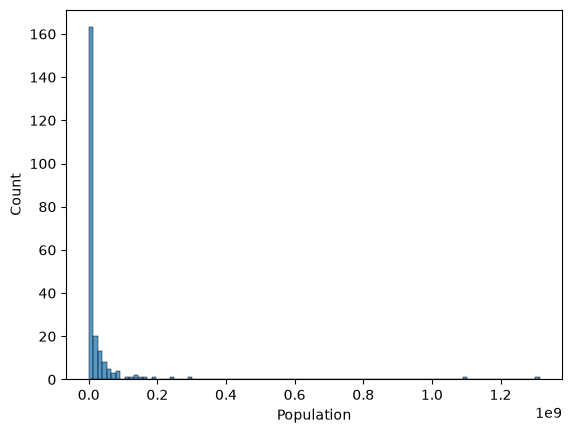

In [5]:
sns.histplot(data=df, x='Population', bins=100);

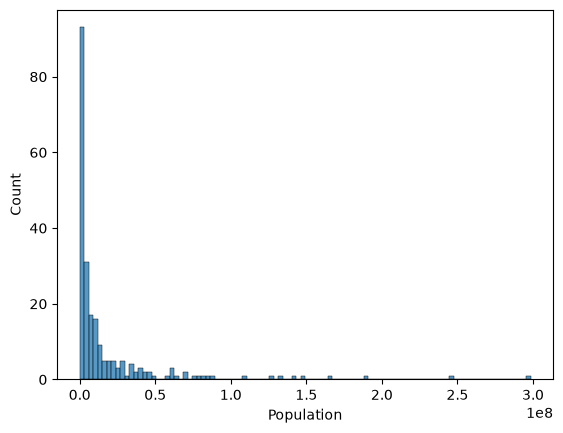

In [6]:
sns.histplot(data=df[df['Population'] < 0.5 * 10**9], x='Population', bins=100);

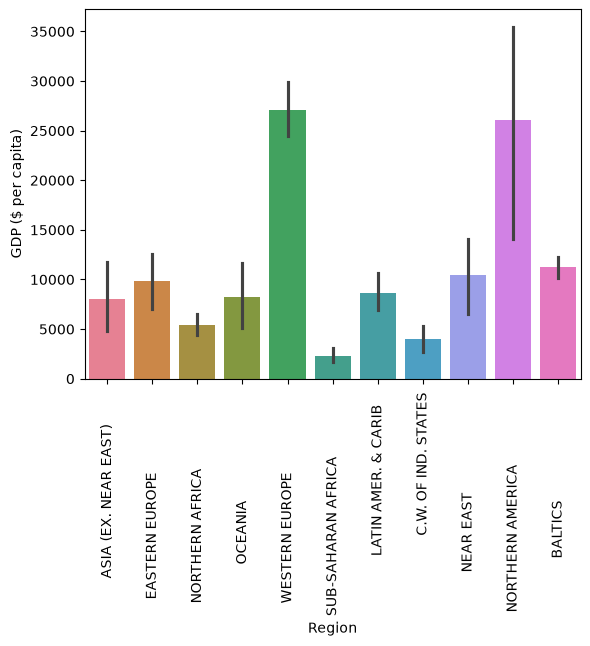

In [7]:
sns.barplot(data=df, x='Region', y='GDP ($ per capita)', hue='Region')
plt.xticks(rotation=90);

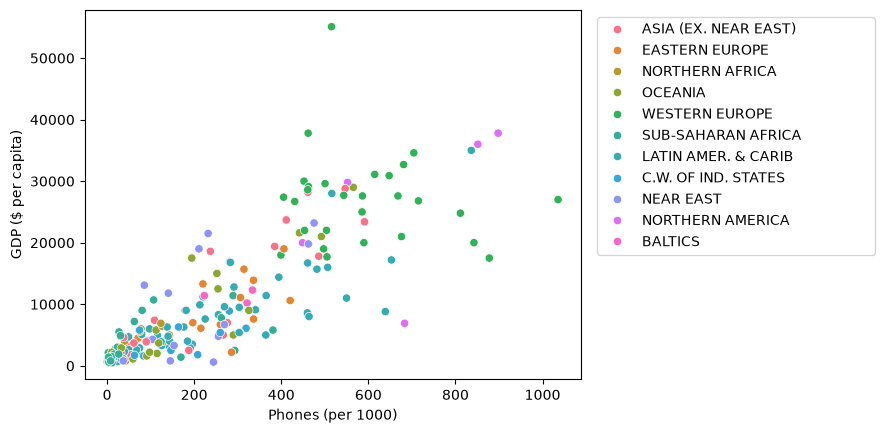

In [8]:
sns.scatterplot(data=df, x='Phones (per 1000)', y='GDP ($ per capita)', hue='Region')
plt.legend(bbox_to_anchor=(1.02, 1));

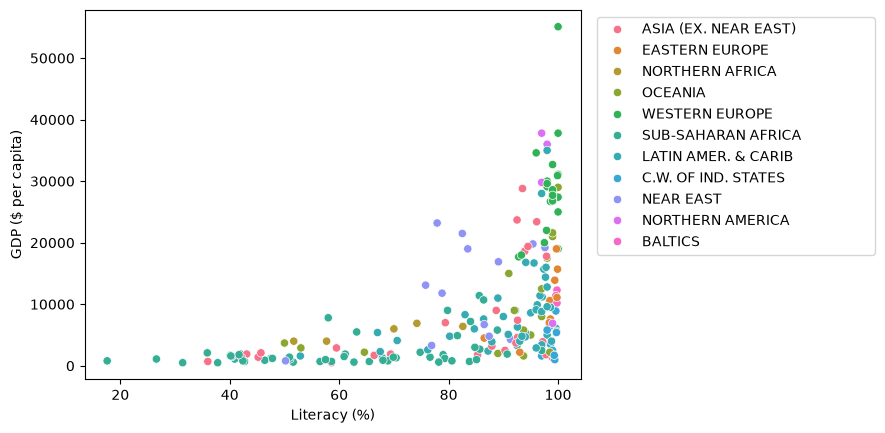

In [9]:
sns.scatterplot(data=df, x='Literacy (%)', y='GDP ($ per capita)', hue='Region')
plt.legend(bbox_to_anchor=(1.02, 1));

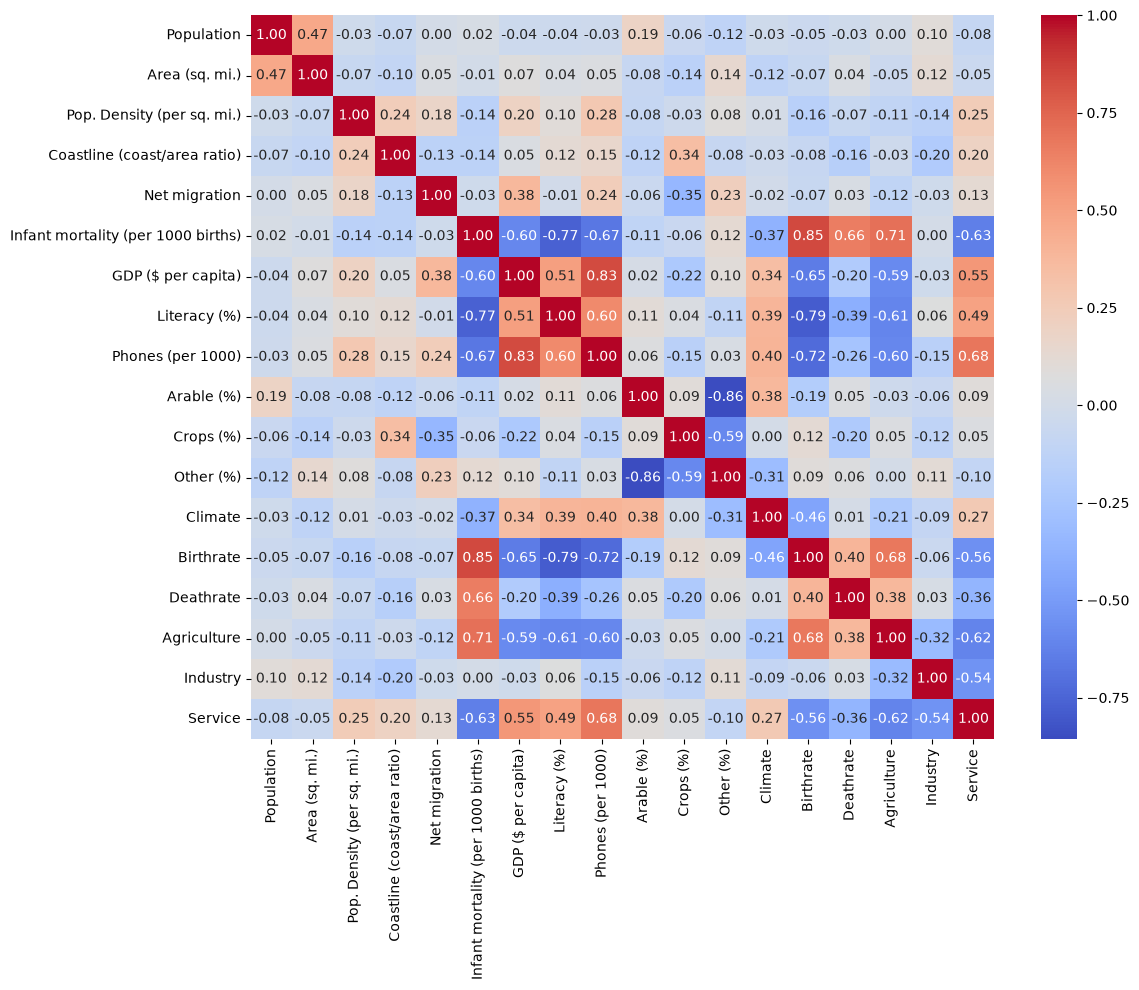

In [10]:
plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f')
plt.tight_layout()

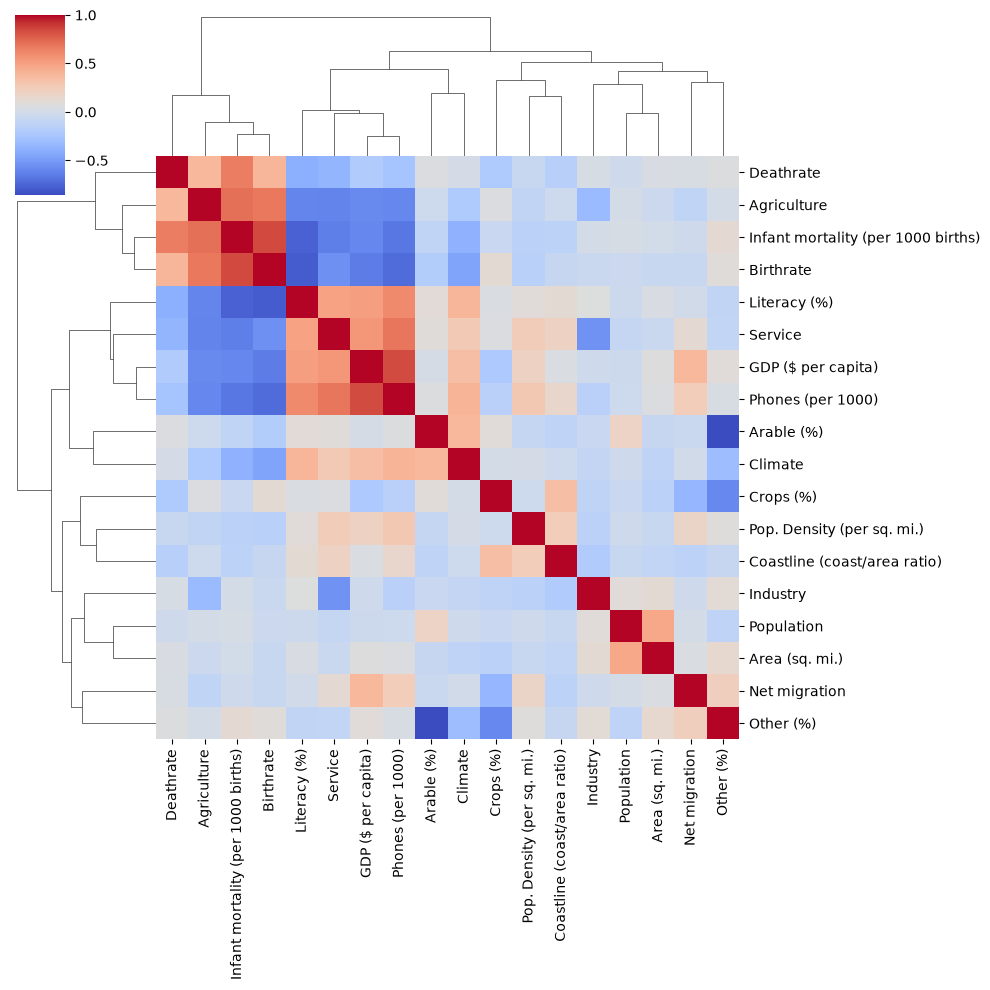

In [11]:
sns.clustermap(df.corr(numeric_only=True), cmap='coolwarm');

## Preprocessing

Missing values are handled in three steps: the 15 tiny territories with no `Agriculture` data get zeros, `Climate` and `Literacy` are filled with the mean of their region, and the few remaining rows with NaN are dropped.

In [12]:
df.isna().sum()

Country                                0
Region                                 0
Population                             0
Area (sq. mi.)                         0
Pop. Density (per sq. mi.)             0
Coastline (coast/area ratio)           0
Net migration                          3
Infant mortality (per 1000 births)     3
GDP ($ per capita)                     1
Literacy (%)                          18
Phones (per 1000)                      4
Arable (%)                             2
Crops (%)                              2
Other (%)                              2
Climate                               22
Birthrate                              3
Deathrate                              4
Agriculture                           15
Industry                              16
Service                               15
dtype: int64

In [13]:
df[df['Agriculture'].isna()]['Country']

3            American Samoa
4                   Andorra
78                Gibraltar
80                Greenland
83                     Guam
134                 Mayotte
140              Montserrat
144                   Nauru
153      N. Mariana Islands
171            Saint Helena
174    St Pierre & Miquelon
177              San Marino
208       Turks & Caicos Is
221       Wallis and Futuna
223          Western Sahara
Name: Country, dtype: str

In [14]:
df[df['Agriculture'].isnull()] = df[df['Agriculture'].isnull()].fillna(0)
df['Climate'] = df.groupby('Region')['Climate'].transform(lambda x: x.fillna(x.mean()))
df['Literacy (%)'] = df.groupby('Region')['Literacy (%)'].transform(lambda x: x.fillna(x.mean()))
df.isna().sum()

Country                               0
Region                                0
Population                            0
Area (sq. mi.)                        0
Pop. Density (per sq. mi.)            0
Coastline (coast/area ratio)          0
Net migration                         1
Infant mortality (per 1000 births)    1
GDP ($ per capita)                    0
Literacy (%)                          0
Phones (per 1000)                     2
Arable (%)                            1
Crops (%)                             1
Other (%)                             1
Climate                               0
Birthrate                             1
Deathrate                             2
Agriculture                           0
Industry                              1
Service                               1
dtype: int64

In [15]:
df = df.dropna()
df.shape

(221, 20)

`Country` is a unique identifier, so it is excluded from the features. `Region` is one-hot encoded and all features are standardized, because they are on very different scales (percentages vs. absolute values).

In [16]:
X = df.drop('Country', axis=1)
X = pd.get_dummies(X, columns=['Region'])
X.head()

,Population,Area (sq. mi.),Pop. Density (per sq. mi.),Coastline (coast/area ratio),Net migration,Infant mortality (per 1000 births),GDP ($ per capita),Literacy (%),Phones (per 1000),Arable (%),...,Region_BALTICS,Region_C.W. OF IND. STATES,Region_EASTERN EUROPE,Region_LATIN AMER. & CARIB,Region_NEAR EAST,Region_NORTHERN AFRICA,Region_NORTHERN AMERICA,Region_OCEANIA,Region_SUB-SAHARAN AFRICA,Region_WESTERN EUROPE
0,31056997,647500,48.0,0.00,23.06,163.07,700.0,36.0,3.2,12.13,...,False,False,False,False,False,False,False,False,False,False
1,3581655,28748,124.6,1.26,-4.93,21.52,4500.0,86.5,71.2,21.09,...,False,False,True,False,False,False,False,False,False,False
2,32930091,2381740,13.8,0.04,-0.39,31.00,6000.0,70.0,78.1,3.22,...,False,False,False,False,False,True,False,False,False,False
3,57794,199,290.4,58.29,-20.71,9.27,8000.0,97.0,259.5,10.00,...,False,False,False,False,False,False,False,True,False,False
4,71201,468,152.1,0.00,6.60,4.05,19000.0,100.0,497.2,2.22,...,False,False,False,False,False,False,False,False,False,True


In [17]:
scaler = StandardScaler()
scaled_X = scaler.fit_transform(X)

## Modeling

K-Means is fitted for K from 2 to 30, recording the sum of squared distances (SSD) for the elbow method and the silhouette score.

In [18]:
ssd = []

for k in range(2, 31):
    model = KMeans(n_clusters=k, random_state=101, n_init=10)
    model.fit(scaled_X)

    ssd.append(model.inertia_)

In [19]:
silhouettes = {}

for k in range(2, 31):
    model = KMeans(n_clusters=k, random_state=101, n_init=10)
    model.fit(scaled_X)

    silhouettes[k] = silhouette_score(scaled_X, model.labels_)

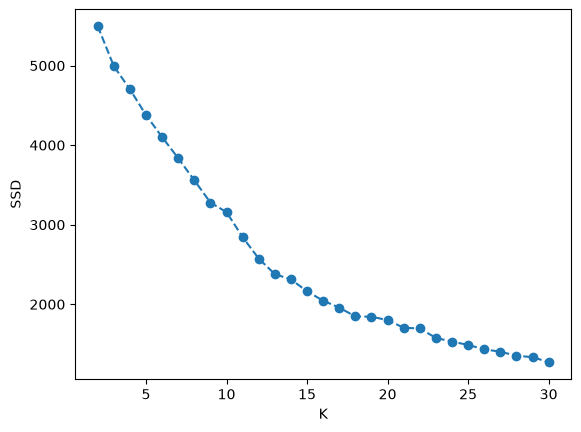

In [20]:
plt.plot(range(2, 31), ssd, 'o--')
plt.xlabel('K')
plt.ylabel('SSD')
plt.savefig('images/elbow_ssd.png', bbox_inches='tight');

In [21]:
best = max(silhouettes.items(), key=lambda item: item[1])
print(best)

(17, 0.34764818631234323)


In [22]:
silhouettes

{2: 0.14637077583875827,
 3: 0.15428485841445772,
 4: 0.17561137209924393,
 5: 0.1918273306802976,
 6: 0.22601630814662135,
 7: 0.24799785299831373,
 8: 0.26722199615558695,
 9: 0.2653813647005241,
 10: 0.2878632585577709,
 11: 0.30432726090575196,
 12: 0.3240269719709318,
 13: 0.3277499138632756,
 14: 0.29556314207362033,
 15: 0.3394886133628798,
 16: 0.3026228832462514,
 17: 0.34764818631234323,
 18: 0.3179867008656191,
 19: 0.31153743147898716,
 20: 0.3120705051102605,
 21: 0.31195991115221716,
 22: 0.2810268144733242,
 23: 0.2735292367733609,
 24: 0.27864454076143513,
 25: 0.2817718287079271,
 26: 0.2832913959289261,
 27: 0.28923452063728705,
 28: 0.25419236508081655,
 29: 0.2701967270972955,
 30: 0.2655716894485714}

### Choosing K

The SSD curve has no sharp elbow, and the silhouette score is highest at K=17 (0.35). Seventeen groups for ~220 countries are not interpretable: many clusters hold only a few countries and differ in small details. K=3 has a lower silhouette (0.15) but gives a clear split by development level, so I use it for interpretation.

In [23]:
model = KMeans(n_clusters=3, random_state=101, n_init=10)
labels = model.fit_predict(scaled_X)

In [24]:
df_transformed = pd.DataFrame(columns=X.columns, data=scaled_X)
df_transformed['labels'] = labels
correlations = df_transformed.corr()['labels'].sort_values().drop('labels')
correlations

Literacy (%)                                 -0.402487
Region_LATIN AMER. & CARIB                   -0.373255
Region_OCEANIA                               -0.245598
Crops (%)                                    -0.244827
Region_C.W. OF IND. STATES                   -0.191406
Phones (per 1000)                            -0.188404
Region_NEAR EAST                             -0.177376
Coastline (coast/area ratio)                 -0.155824
Region_NORTHERN AFRICA                       -0.150323
Service                                      -0.122332
Population                                   -0.073474
GDP ($ per capita)                           -0.052361
Industry                                     -0.043662
Area (sq. mi.)                               -0.037016
Region_NORTHERN AMERICA                      -0.026213
Region_ASIA (EX. NEAR EAST)                  -0.000607
Pop. Density (per sq. mi.)                    0.007805
Climate                                       0.026251
Region_BAL

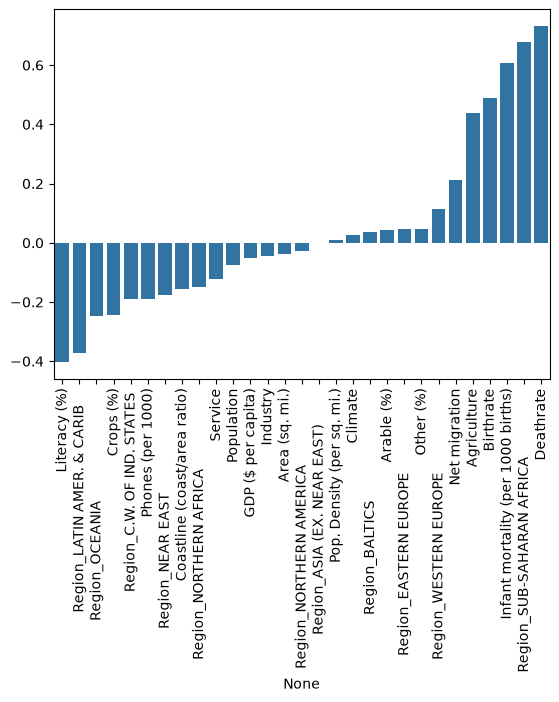

In [25]:
sns.barplot(x=correlations.index, y=correlations.values)
plt.xticks(rotation=90);

Cluster means on the standardized features, and cluster sizes:

In [26]:
df_transformed.groupby('labels').mean()

,Population,Area (sq. mi.),Pop. Density (per sq. mi.),Coastline (coast/area ratio),Net migration,Infant mortality (per 1000 births),GDP ($ per capita),Literacy (%),Phones (per 1000),Arable (%),...,Region_BALTICS,Region_C.W. OF IND. STATES,Region_EASTERN EUROPE,Region_LATIN AMER. & CARIB,Region_NEAR EAST,Region_NORTHERN AFRICA,Region_NORTHERN AMERICA,Region_OCEANIA,Region_SUB-SAHARAN AFRICA,Region_WESTERN EUROPE
labels,,,,,,,,,,,,,,,,,,,,,
0,0.081329,0.033244,-0.099718,0.129412,-0.309367,-0.294793,-0.287747,0.165291,-0.158354,-0.149796,...,-0.117309,0.197702,-0.187444,0.389234,0.195778,0.165549,-0.030977,0.249794,-0.419427,-0.365148
1,-0.083290,-0.011319,0.369909,-0.005894,0.540310,-0.809650,1.311121,0.654636,1.240921,0.450153,...,0.345643,-0.160814,0.592235,-0.328271,-0.198849,-0.167054,0.208113,-0.190954,-0.547723,1.075884
2,-0.080801,-0.056596,-0.178634,-0.259900,0.075598,1.445601,-0.768200,-1.018648,-0.961376,-0.158912,...,-0.117309,-0.239617,-0.228869,-0.459663,-0.196220,-0.167054,-0.152145,-0.315440,1.430164,-0.365148


In [27]:
df_transformed['labels'].value_counts()

labels
0    111
1     56
2     54
Name: count, dtype: int64

In [28]:
df['K=3 Clusters'] = labels.astype(str)
df[df['K=3 Clusters'] == '1']['Country']

4                   Andorra
10                    Aruba
11                Australia
12                  Austria
17                 Barbados
18                  Belarus
19                  Belgium
22                  Bermuda
25     Bosnia & Herzegovina
28       British Virgin Is.
30                 Bulgaria
36                   Canada
38           Cayman Islands
50                  Croatia
53           Czech Republic
54                  Denmark
64                  Estonia
66            Faroe Islands
68                  Finland
69                   France
76                  Germany
78                Gibraltar
79                   Greece
91                Hong Kong
92                  Hungary
93                  Iceland
98                  Ireland
99              Isle of Man
100                  Israel
101                   Italy
103                   Japan
104                  Jersey
110            Korea, South
114                  Latvia
119           Liechtenstein
120               Li

The same means for a few key indicators in their original units, which are easier to read:

In [29]:
key_cols = ['GDP ($ per capita)', 'Literacy (%)', 'Infant mortality (per 1000 births)',
            'Phones (per 1000)', 'Birthrate', 'Agriculture', 'Service', 'Net migration']
df.groupby('K=3 Clusters')[key_cols].mean().round(2)

,GDP ($ per capita),Literacy (%),Infant mortality (per 1000 births),Phones (per 1000),Birthrate,Agriculture,Service,Net migration
K=3 Clusters,,,,,,,,
0,6693.69,84.96,25.17,192.38,20.36,0.11,0.51,-1.52
1,22701.79,96.10,6.90,499.13,10.79,0.04,0.66,2.62
2,1883.33,58.03,86.96,16.34,37.24,0.30,0.41,0.36


What the three clusters represent:
- **Cluster 1 - developed (56 countries):** Western and Eastern Europe, North America, Japan, South Korea, Australia. Highest GDP per capita (~$22.7k), literacy 96%, infant mortality ~7 per 1000, ~500 phones per 1000 people, low birthrate and positive net migration.
- **Cluster 0 - developing (111 countries):** Latin America, most of Asia (incl. China and India), the Middle East, North Africa, former USSR and Oceania. Middle values on every indicator: GDP ~$6.7k, literacy 85%, infant mortality ~25.
- **Cluster 2 - least developed (54 countries):** 45 of them are in Sub-Saharan Africa, plus Afghanistan, Nepal, Laos, Cambodia and Haiti. GDP ~$1.9k, literacy 58%, infant mortality ~87 and the highest birth and death rates.

For comparison, a more fine-grained model with K=14:

In [30]:
model = KMeans(n_clusters=14, random_state=101, n_init=10)
labels = model.fit_predict(scaled_X)
df['K=14 Clusters'] = labels.astype(str)

## Results

Clusters on a world map. Country names are mapped to ISO-3 codes for plotly; 36 countries whose names are spelled differently in the ISO table (e.g. Czech Republic, Netherlands, Philippines) are left blank. The interactive maps are also saved as static PNGs so they render on GitHub.

In [31]:
iso_codes = pd.read_csv('data/country_iso_codes.csv', index_col='Country')
iso_dict = iso_codes['ISO Code'].to_dict()
df['ISO'] = df['Country'].map(iso_dict)
df['ISO'].isna().sum()

np.int64(36)

In [32]:
fig = px.choropleth(df, locations='ISO', hover_name='Country', color='K=3 Clusters',
                    category_orders={'K=3 Clusters': ['0', '1', '2']})
fig.write_image('images/clusters_k3.png', width=1000, height=500)
fig.show()

Resorting to unclean kill browser.


![K=3 clusters](images/clusters_k3.png)

In [33]:
fig = px.choropleth(df, locations='ISO', hover_name='Country', color='K=14 Clusters',
                    color_discrete_sequence=px.colors.qualitative.Light24,
                    category_orders={'K=14 Clusters': [str(i) for i in range(14)]})
fig.write_image('images/clusters_k14.png', width=1000, height=500)
fig.show()

![K=14 clusters](images/clusters_k14.png)

## Conclusions

K-Means on standardized country indicators mainly separates countries by development level: literacy, infant mortality, phones per 1000 and GDP per capita differ most between clusters. K=3 gives three readable groups (developed, developing, least developed) that also match geography on the map, while K=14 shows finer regional differences but is harder to describe.